### Generalized Least Squares Lab

In this lab, you will fit a GLS model to a data set from the chemical and taste analysis of cheddar cheese. To begin, import the data set below.

In [1]:
load('cheddar.rda')
cheddar <- cheddar

We will then add a new column, `time`, to the data. 

In [2]:
cheddar$time <- 1: nrow(cheddar)

Now, fit a linear model predicting taste using data for `Acetic`, `H2S`, and `Lactic`. Save your model to `lmod`.

In [3]:
lmod <- lm(taste ~ Acetic + H2S + Lactic, data = cheddar)
summary(lmod)


Call:
lm(formula = taste ~ Acetic + H2S + Lactic, data = cheddar)

Residuals:
    Min      1Q  Median      3Q     Max 
-17.390  -6.612  -1.009   4.908  25.449 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)   
(Intercept) -28.8768    19.7354  -1.463  0.15540   
Acetic        0.3277     4.4598   0.073  0.94198   
H2S           3.9118     1.2484   3.133  0.00425 **
Lactic       19.6705     8.6291   2.280  0.03108 * 
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 10.13 on 26 degrees of freedom
Multiple R-squared:  0.6518,	Adjusted R-squared:  0.6116 
F-statistic: 16.22 on 3 and 26 DF,  p-value: 3.81e-06


In [4]:
res <- residuals(lmod)
n <- length(res)
cor(res[-1], res[-n])

[1] 0.1787081

Now, plot the residuals from the model against time using `plot()`. What do you see? 

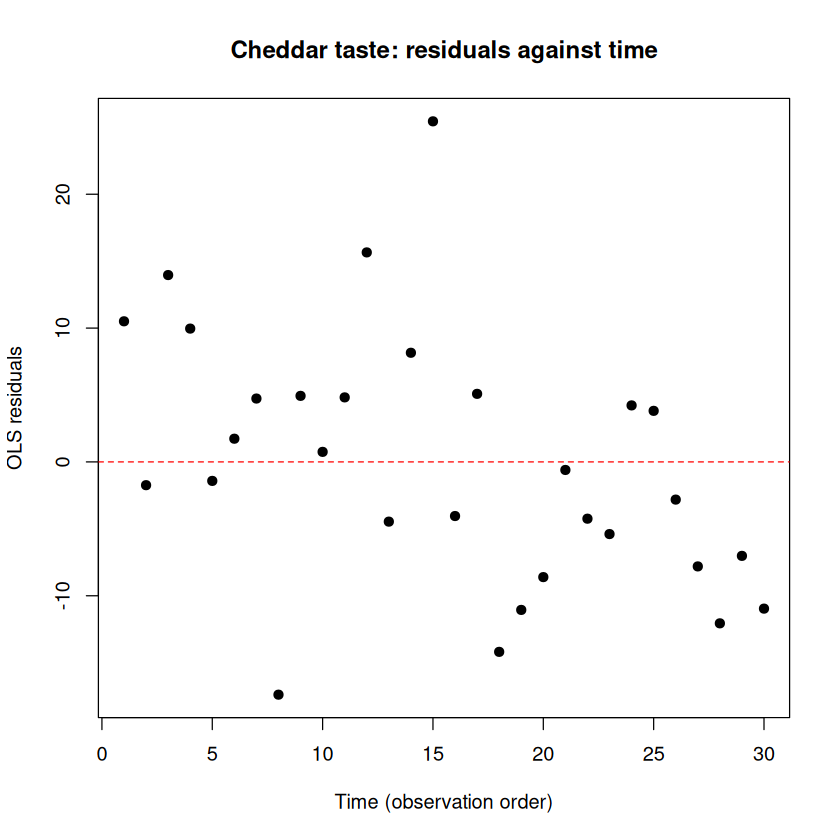

In [5]:
model_plot <- plot(x = cheddar$time, y = residuals(lmod),
                   xlab = "Time (observation order)", ylab = "OLS residuals",
                   main = "Cheddar taste: residuals against time", pch = 19)
abline(h = 0, col = "red", lty = 2)

The residuals tend to be positive earlier and negative later, with some runs of residuals on the same side of zero. This suggests a possible time pattern, although there is substantial scatter. The lag-one residual correlation is approximately 0.179, indicating weak positive association between consecutive residuals. The plot alone does not establish correlated errors.

Finally, fit a GLS model using AR(1) correlation. Is there evidence of correlation between the errors? Calculate the confidence interval on that using the `intervals` function.

In [6]:
library(nlme)

glmod <- gls(taste ~ Acetic + H2S + Lactic,
             correlation = corAR1(form = ~ time), data = cheddar)
summary(glmod)

Generalized least squares fit by REML
  Model: taste ~ Acetic + H2S + Lactic 
  Data: cheddar 
     AIC      BIC  logLik
  214.94 222.4886 -101.47

Correlation Structure: AR(1)
 Formula: ~time 
 Parameter estimate(s):
      Phi 
0.2641944 

Coefficients:
                 Value Std.Error   t-value p-value
(Intercept) -30.332472 20.273077 -1.496195  0.1466
Acetic        1.436411  4.876581  0.294553  0.7707
H2S           4.058880  1.314283  3.088284  0.0047
Lactic       15.826468  9.235404  1.713674  0.0985

 Correlation: 
       (Intr) Acetic H2S   
Acetic -0.899              
H2S     0.424 -0.395       
Lactic  0.063 -0.416 -0.435

Standardized residuals:
        Min          Q1         Med          Q3         Max 
-1.64546468 -0.63861716 -0.06641714  0.52255676  2.41323021 

Residual standard error: 10.33276 
Degrees of freedom: 30 total; 26 residual

In [7]:
glmod_intervals <- intervals(glmod, which = "var-cov")
glmod_intervals

Approximate 95% confidence intervals

 Correlation structure:
         lower      est.     upper
Phi -0.1690759 0.2641944 0.6118917

 Residual standard error:
    lower      est.     upper 
 7.626441 10.332756 13.999433 

The GLS model estimates the AR(1) correlation parameter as $\hat{\phi} = 0.264$. Its approximate 95% confidence interval is $(-0.169, 0.612)$. Because this interval includes zero, there is insufficient evidence of nonzero AR(1) error correlation at the 5% level. The positive estimate is consistent with the weak association in the OLS residuals, but unlike the global warming practice example, the interval does not provide clear evidence of correlated errors. Here, `time` represents the assigned observation order rather than measured elapsed time.